# Modelado: predicción del rendimiento en matemáticas

Este notebook continúa el EDA ya realizado. **No repite el análisis exploratorio.** Resuelve la preparación de datos y definición de variables (punto 3), la separación (4), el entrenamiento (5), la evaluación (6), cinco predicciones (7) y una automatización (8).

El objetivo es predecir `TestScore_Math`: es un problema de **regresión**, porque el resultado es un puntaje numérico, no una clase.

**Antes de empezar:** sube el mismo CSV usado en el EDA y ajusta la ruta. El CSV real no acompaña al notebook original, por lo que las métricas y predicciones se calcularán cuando lo ejecutes. No se presentan resultados inventados.

## 1. Librerías
Si falta alguna librería, ejecuta la celda de instalación quitando el símbolo `#`.

In [1]:
# %pip install pandas numpy matplotlib scikit-learn joblib

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEMILLA = 42
RUTA_CSV = "../data/raw/train.csv"
# El original contiene millones de filas. Este límite hace viable la práctica.
# Cambia a None para usar todo el archivo, si tienes memoria y tiempo suficientes.
MAX_FILAS = 100_000

## 2. Cargar y seleccionar las variables
Se carga el CSV porque este notebook debe funcionar sin ejecutar antes el EDA.

- **Dependiente:** puntaje de matemáticas.
- **Independientes:** edad, grado, contexto socioeconómico, educación parental, estudio, asistencia, internet, apoyo parental y actividades extracurriculares.

No incluimos GPA, lectura ni ciencias para evitar usar resultados que podrían no estar disponibles antes de la evaluación. Las candidatas deben confirmarse con el diccionario y las fechas de medición. No se utilizan género ni grupo étnico como predictores en esta práctica; eso por sí solo no garantiza equidad.

In [3]:
objetivo = "TestScore_Math"
numericas = ["Age", "StudyHours", "AttendanceRate"]
categoricas = ["Grade", "SES_Quartile", "ParentalEducation", "InternetAccess", "ParentSupport", "Extracurricular"]
variables = numericas + categoricas

nombres_es = {
    "Age": "Edad", "StudyHours": "Tiempo de estudio", "AttendanceRate": "Tasa de asistencia",
    "Grade": "Grado escolar", "SES_Quartile": "Cuartil socioeconómico",
    "ParentalEducation": "Educación de los padres", "InternetAccess": "Acceso a internet",
    "ParentSupport": "Apoyo parental", "Extracurricular": "Participación extracurricular"
}

# Solo cargar las columnas que necesitamos.
df = pd.read_csv(RUTA_CSV, usecols=variables + [objetivo])
print("Registros cargados:", len(df))
if MAX_FILAS is not None and len(df) > MAX_FILAS:
    df = df.sample(n=MAX_FILAS, random_state=SEMILLA)
    print("Se trabaja con una muestra aleatoria de", len(df), "registros.")
    print("Los resultados se refieren a esta muestra, no al entrenamiento sobre todo el archivo.")
print("Variables independientes:")
display(pd.DataFrame({"Columna original": variables, "Nombre en español": [nombres_es[c] for c in variables]}))

Registros cargados: 8000774
Se trabaja con una muestra aleatoria de 100000 registros.
Los resultados se refieren a esta muestra, no al entrenamiento sobre todo el archivo.
Variables independientes:


,Columna original,Nombre en español
0,Age,Edad
1,StudyHours,Tiempo de estudio
2,AttendanceRate,Tasa de asistencia
3,Grade,Grado escolar
4,SES_Quartile,Cuartil socioeconómico
5,ParentalEducation,Educación de los padres
6,InternetAccess,Acceso a internet
7,ParentSupport,Apoyo parental
8,Extracurricular,Participación extracurricular


## 3. Preparación inicial
Convertimos las columnas numéricas y quitamos únicamente las filas sin un puntaje válido: no se puede entrenar si no conocemos la respuesta.

No eliminamos automáticamente filas repetidas ni puntajes extremos. La imputación y el escalado se aprenderán después, solo con entrenamiento. Los códigos categóricos se conservan; confirmar su significado y las unidades de estudio y asistencia con la fuente.

In [4]:
for columna in numericas + [objetivo]:
    df[columna] = pd.to_numeric(df[columna], errors="coerce")
    df[columna] = df[columna].replace([np.inf, -np.inf], np.nan)

sin_puntaje = df[objetivo].isna().sum()
df = df.dropna(subset=[objetivo]).copy()
print("Filas excluidas por no tener puntaje válido:", sin_puntaje)
print("Filas disponibles para modelar:", len(df))
if len(df) < 30:
    raise ValueError("Se necesitan al menos 30 registros válidos para esta práctica.")

# Unificar el tipo de las categorías; los faltantes se mantienen como NaN.
for columna in categoricas:
    df[columna] = df[columna].map(lambda valor: str(valor) if pd.notna(valor) else np.nan)

X = df[variables]
y = df[objetivo]
display(X.isna().sum().rename(index=nombres_es).to_frame("Faltantes antes de imputar"))

Filas excluidas por no tener puntaje válido: 0
Filas disponibles para modelar: 100000


,Faltantes antes de imputar
Edad,0
Tiempo de estudio,0
Tasa de asistencia,0
Grado escolar,0
Cuartil socioeconómico,0
Educación de los padres,0
Acceso a internet,0
Apoyo parental,0
Participación extracurricular,0


## 4. Separar entrenamiento, validación y test
- **60 % entrenamiento:** aprender los modelos.
- **20 % validación:** elegir entre los modelos.
- **20 % test:** evaluar al ganador, sin usar test para elegirlo.

La división aleatoria supone que cada fila representa un estudiante independiente. Si existen registros repetidos de un mismo estudiante, se debe dividir por estudiante; si se predicen evaluaciones futuras, conviene una división temporal. El dataset usado no incluye esas claves en las variables seleccionadas.

Como el EDA ya observó el archivo, este test sirve para la práctica; una evaluación institucional definitiva debería incluir datos nuevos no explorados.

In [5]:
X_desarrollo, X_test, y_desarrollo, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEMILLA
)
X_train, X_validacion, y_train, y_validacion = train_test_split(
    X_desarrollo, y_desarrollo, test_size=0.25, random_state=SEMILLA
)

display(pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Validación", "Test"],
    "Cantidad de registros": [len(X_train), len(X_validacion), len(X_test)]
}))
columnas_vacias = X_train.columns[X_train.isna().all()].tolist()
if columnas_vacias:
    raise ValueError("Estas variables no tienen datos en entrenamiento: " + str(columnas_vacias))

,Conjunto,Cantidad de registros
0,Entrenamiento,60000
1,Validación,20000
2,Test,20000


## 5. Preparar los datos dentro de cada modelo
Para las numéricas: completar faltantes con la mediana y escalar. Para las categóricas: completar con la categoría más frecuente y convertir las categorías en columnas numéricas.

`Pipeline` agrupa la preparación y el modelo. Así se aprende la preparación con entrenamiento y se aplica la misma transformación a validación, test y estudiantes nuevos.

Comparamos una referencia que siempre predice el promedio, una regresión lineal y un bosque aleatorio. La referencia permite comprobar si los modelos aportan algo frente a una predicción muy simple.

In [6]:
preparacion_numerica = Pipeline([
    ("completar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler())
])
preparacion_categorica = Pipeline([
    ("completar", SimpleImputer(strategy="most_frequent")),
    ("codificar", OneHotEncoder(handle_unknown="ignore"))
])

preparacion = ColumnTransformer([
    ("numericas", preparacion_numerica, numericas),
    ("categoricas", preparacion_categorica, categoricas)
])

modelos = {
    "Referencia: promedio": DummyRegressor(strategy="mean"),
    "Regresión lineal": LinearRegression(),
    "Bosque aleatorio": RandomForestRegressor(
        n_estimators=60, max_depth=12, min_samples_leaf=5,
        random_state=SEMILLA, n_jobs=-1
    )
}

## 6. Entrenar y comparar en validación
- **MAE:** error absoluto medio, en puntos. Menor es mejor.
- **RMSE:** error en puntos que penaliza más los errores grandes. Menor es mejor.
- **R²:** compara con predecir una media; 1 es perfecto, 0 indica un resultado similar a esa referencia y puede ser negativo.

Elegimos el menor MAE de validación. También mostramos el MAE de entrenamiento: si es mucho menor que el de validación, puede haber sobreajuste. No hay un error “aceptable” universal; la institución debe definirlo.

,Modelo,MAE entrenamiento,MAE validación,RMSE validación,R² validación
1,Regresión lineal,4.560,4.567,5.696,0.675
2,Bosque aleatorio,4.125,4.609,5.747,0.669
0,Referencia: promedio,7.999,7.979,9.988,-0.000


Modelo seleccionado con validación: Regresión lineal


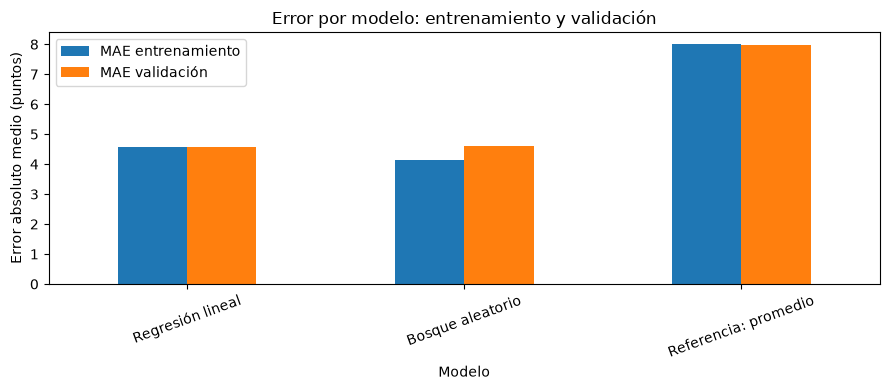

In [7]:
from sklearn.base import clone

resultados = []
modelos_entrenados = {}
for nombre, estimador in modelos.items():
    modelo = Pipeline([
        ("preparacion", clone(preparacion)),
        ("modelo", clone(estimador))
    ])
    modelo.fit(X_train, y_train)
    pred_train = modelo.predict(X_train)
    pred_validacion = modelo.predict(X_validacion)
    resultados.append({
        "Modelo": nombre,
        "MAE entrenamiento": mean_absolute_error(y_train, pred_train),
        "MAE validación": mean_absolute_error(y_validacion, pred_validacion),
        "RMSE validación": np.sqrt(mean_squared_error(y_validacion, pred_validacion)),
        "R² validación": r2_score(y_validacion, pred_validacion)
    })
    modelos_entrenados[nombre] = modelo

comparacion = pd.DataFrame(resultados).sort_values("MAE validación")
display(comparacion.round(3))
nombre_mejor = comparacion.iloc[0]["Modelo"]
print("Modelo seleccionado con validación:", nombre_mejor)

comparacion.set_index("Modelo")[["MAE entrenamiento", "MAE validación"]].plot.bar(figsize=(9, 4))
plt.title("Error por modelo: entrenamiento y validación")
plt.ylabel("Error absoluto medio (puntos)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 7. Evaluación final en test
Reentrenamos el modelo elegido con entrenamiento + validación, sin usar test. Después medimos su desempeño final y lo comparamos con una referencia ajustada sobre los mismos datos de desarrollo.

In [8]:
modelo_final = clone(modelos_entrenados[nombre_mejor])
modelo_final.fit(X_desarrollo, y_desarrollo)
pred_test = modelo_final.predict(X_test)

referencia = DummyRegressor(strategy="mean")
referencia.fit(np.zeros((len(y_desarrollo), 1)), y_desarrollo)
pred_referencia = referencia.predict(np.zeros((len(y_test), 1)))

metricas_test = []
for nombre, predicciones in [(nombre_mejor, pred_test), ("Referencia: promedio", pred_referencia)]:
    metricas_test.append({
        "Modelo": nombre,
        "MAE test": mean_absolute_error(y_test, predicciones),
        "RMSE test": np.sqrt(mean_squared_error(y_test, predicciones)),
        "R² test": r2_score(y_test, predicciones)
    })
display(pd.DataFrame(metricas_test).round(3))

mae_final = mean_absolute_error(y_test, pred_test)
mae_base = mean_absolute_error(y_test, pred_referencia)
print("Error absoluto medio del modelo seleccionado:", round(mae_final, 2), "puntos.")
if mae_final < mae_base:
    print("En este test mejora el MAE de la referencia. Esto no garantiza utilidad institucional.")
else:
    print("En este test no mejora el MAE de la referencia: revisar variables y datos antes de usarlo.")
print("No modificar ni elegir el modelo con este test; nuevas mejoras requieren otra validación.")

,Modelo,MAE test,RMSE test,R² test
0,Regresión lineal,4.546,5.693,0.676
1,Referencia: promedio,8.009,9.995,-0.000


Error absoluto medio del modelo seleccionado: 4.55 puntos.
En este test mejora el MAE de la referencia. Esto no garantiza utilidad institucional.
No modificar ni elegir el modelo con este test; nuevas mejoras requieren otra validación.


,Puntaje real,Puntaje estimado,Error absoluto
0,84.22,80.38,3.84
1,69.56,69.72,0.16
2,89.01,83.54,5.48
3,90.63,84.48,6.15
4,70.54,69.58,0.96
5,69.38,78.48,9.10
6,72.96,74.24,1.28
7,80.10,78.45,1.65
8,82.69,69.69,13.01
9,94.31,91.89,2.42


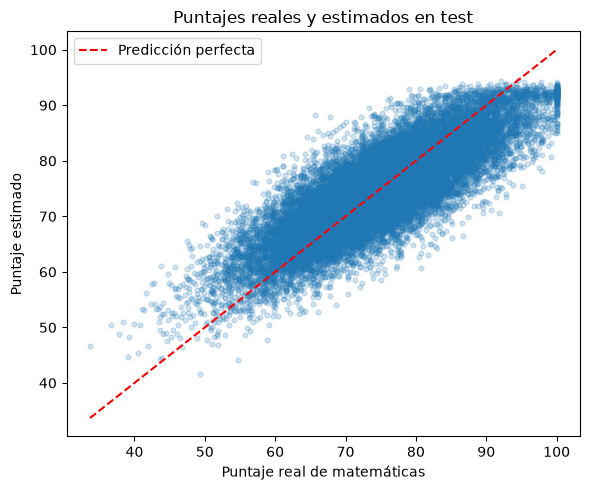

In [9]:
# Mostrar algunos resultados reales frente a los estimados.
comparacion_test = pd.DataFrame({
    "Puntaje real": y_test.to_numpy(),
    "Puntaje estimado": pred_test
})
comparacion_test["Error absoluto"] = abs(comparacion_test["Puntaje real"] - comparacion_test["Puntaje estimado"])
display(comparacion_test.head(10).round(2))

plt.figure(figsize=(6, 5))
plt.scatter(y_test, pred_test, alpha=0.2, s=12)
limite_min = min(y_test.min(), pred_test.min())
limite_max = max(y_test.max(), pred_test.max())
plt.plot([limite_min, limite_max], [limite_min, limite_max], "r--", label="Predicción perfecta")
plt.xlabel("Puntaje real de matemáticas")
plt.ylabel("Puntaje estimado")
plt.title("Puntajes reales y estimados en test")
plt.legend()
plt.tight_layout()
plt.show()

### ¿Fueron suficientes los pasos anteriores?
Después de ejecutar, responder con las tablas:
1. ¿El mejor modelo supera a la referencia en validación y qué sucede en test?
2. ¿Hay mucha diferencia entre error de entrenamiento y validación?
3. ¿El MAE final es tolerable para el uso propuesto? Acordar un criterio institucional.

El procedimiento permite construir y comparar modelos, pero no prueba que estén listos para decisiones reales. Si no mejoran la referencia, puede faltar información relevante, existir mucho ruido o no haber una relación predictiva útil. Verificar unidades, momento de medición y calidad de datos antes de aumentar la complejidad. No se midió bienestar emocional ni se evaluó equidad por grupos en este notebook.

## 8. Generar cinco predicciones con datos nuevos de ejemplo
Como no se proporcionaron estudiantes nuevos, construimos **cinco perfiles ficticios**, no resultados reales ni registros tomados del test. Usamos cuantiles y categorías observadas en entrenamiento para evitar inventar códigos desconocidos. Cada columna se combina de forma independiente: las combinaciones deben revisarse antes de usarlas como casos realistas.

La tabla muestra nombres de variables en español, pero el modelo conserva las columnas originales. Para estudiantes reales, reemplaza estos ejemplos por sus datos. Las estimaciones no son notas oficiales ni incluyen intervalos de incertidumbre.

In [10]:
nuevos_estudiantes = pd.DataFrame(index=range(5), columns=variables)
for columna in numericas:
    nuevos_estudiantes[columna] = X_train[columna].quantile([0.20, 0.35, 0.50, 0.65, 0.80]).to_numpy()
for columna in categoricas:
    categorias_observadas = X_train[columna].dropna().unique()
    nuevos_estudiantes[columna] = [categorias_observadas[i % len(categorias_observadas)] for i in range(5)]

predicciones_nuevas = modelo_final.predict(nuevos_estudiantes)
salida_ejemplos = nuevos_estudiantes.rename(columns=nombres_es).copy()
salida_ejemplos.insert(0, "Caso ficticio", range(1, 6))
salida_ejemplos["Puntaje estimado de matemáticas"] = predicciones_nuevas
print("CINCO EJEMPLOS FICTICIOS — no corresponden a estudiantes nuevos reales")
display(salida_ejemplos.round(2))

CINCO EJEMPLOS FICTICIOS — no corresponden a estudiantes nuevos reales


,Caso ficticio,Edad,Tiempo de estudio,Tasa de asistencia,Grado escolar,Cuartil socioeconómico,Educación de los padres,Acceso a internet,Apoyo parental,Participación extracurricular,Puntaje estimado de matemáticas
0,1,14.0,0.71,0.86,9,3,HS,1,0,1,67.64
1,2,15.0,0.86,0.88,12,4,Bachelors+,0,1,0,71.60
2,3,16.0,1.00,0.90,11,2,SomeCollege,1,0,1,75.13
3,4,17.0,1.14,0.92,10,1,<HS,0,1,0,78.44
4,5,18.0,1.30,0.94,9,3,HS,1,0,1,82.57


## 9. Automatización: predecir desde un CSV
**Propuesta implementada:** guardar la preparación y el modelo juntos, y crear una función que lea un CSV de estudiantes, revise sus columnas, aplique el modelo y exporte los puntajes estimados.

La automatización no vuelve a entrenar: reutiliza el modelo guardado. Los nuevos datos deben utilizar las mismas unidades y códigos que el dataset original. Una categoría desconocida se rechaza para solicitar su revisión. El archivo de entrada no necesita el puntaje de matemáticas.

La función está pensada para el mismo entorno de Python y versiones de librerías del entrenamiento. Cargar solamente modelos de confianza con joblib. Una automatización técnica no autoriza el uso del modelo para calificar ni tomar decisiones sin revisión humana.

In [11]:
# Guardar modelo, columnas y categorías admitidas.
paquete = {
    "modelo": modelo_final,
    "variables": variables,
    "numericas": numericas,
    "categoricas": categoricas,
    "categorias_admitidas": {c: X_desarrollo[c].dropna().unique().tolist() for c in categoricas},
    "nombre_modelo": nombre_mejor
}
joblib.dump(paquete, "modelo_matematicas.joblib")
print("Modelo y preparación guardados correctamente.")

Modelo y preparación guardados correctamente.


In [12]:
def predecir_desde_csv(ruta_entrada, ruta_salida, ruta_modelo="modelo_matematicas.joblib"):
    paquete = joblib.load(ruta_modelo)
    datos = pd.read_csv(ruta_entrada)
    faltantes = [c for c in paquete["variables"] if c not in datos.columns]
    if faltantes:
        raise ValueError("Faltan columnas obligatorias: " + str(faltantes))
    if datos.empty:
        raise ValueError("El CSV no contiene estudiantes.")

    entradas = datos[paquete["variables"]].copy()
    for columna in paquete["numericas"]:
        valores = pd.to_numeric(entradas[columna], errors="coerce")
        errores = entradas[columna].notna() & valores.isna()
        if errores.any() or np.isinf(valores).any():
            raise ValueError("Hay valores numéricos no válidos en: " + columna)
        entradas[columna] = valores

    for columna in paquete["categoricas"]:
        entradas[columna] = entradas[columna].map(lambda v: str(v) if pd.notna(v) else np.nan)
        desconocidas = set(entradas[columna].dropna()) - set(paquete["categorias_admitidas"][columna])
        if desconocidas:
            raise ValueError("Revisar códigos nuevos en " + columna + ": " + str(desconocidas))

    datos["Puntaje_estimado_matematicas"] = paquete["modelo"].predict(entradas)
    datos.to_csv(ruta_salida, index=False)
    print("Registros procesados:", len(datos))
    print("Predicciones exportadas correctamente.")
    return datos

In [13]:
# Demostración completa con los cinco perfiles ficticios.
# Se usa el formato decimal de los códigos originales para conservar sus etiquetas.
nuevos_estudiantes.to_csv("estudiantes_nuevos_ejemplo.csv", index=False)
resultado_automatico = predecir_desde_csv(
    "estudiantes_nuevos_ejemplo.csv", "predicciones_ejemplo.csv"
)
display(resultado_automatico.rename(columns={
    **nombres_es, "Puntaje_estimado_matematicas": "Puntaje estimado de matemáticas"
}).round(2))

# Para procesar un archivo real, ajustar las rutas y quitar el comentario:
# resultado_real = predecir_desde_csv("estudiantes_nuevos.csv", "predicciones_reales.csv")

Registros procesados: 5
Predicciones exportadas correctamente.


,Edad,Tiempo de estudio,Tasa de asistencia,Grado escolar,Cuartil socioeconómico,Educación de los padres,Acceso a internet,Apoyo parental,Participación extracurricular,Puntaje estimado de matemáticas
0,14.0,0.71,0.86,9,3,HS,1,0,1,67.64
1,15.0,0.86,0.88,12,4,Bachelors+,0,1,0,71.60
2,16.0,1.00,0.90,11,2,SomeCollege,1,0,1,75.13
3,17.0,1.14,0.92,10,1,<HS,0,1,0,78.44
4,18.0,1.30,0.94,9,3,HS,1,0,1,82.57


## 10. Conclusiones para completar después de ejecutar
- Modelo seleccionado con validación: **[completar]**.
- MAE y RMSE final en test: **[completar]** puntos; R²: **[completar]**.
- Comparación con la referencia: **[completar]**.
- Evidencia de posible sobreajuste: **[completar según entrenamiento y validación]**.
- Se generaron cinco predicciones para perfiles ficticios y se implementó una función reutilizable para procesar un CSV.
- Antes de un uso real: confirmar representatividad, independencia de estudiantes, escalas, desempeño en datos nuevos, equidad y utilidad educativa. El modelo apoya el análisis, no reemplaza el criterio docente.

### Resumen de la consigna
| Punto | Ubicación |
|---|---|
| 1. Carga | EDA y carga independiente en este notebook |
| 2. Análisis exploratorio y gráficos | Notebook EDA ya terminado |
| 3. Preparación y selección de variables | Secciones 2, 3 y 5 |
| 4. Separación de datos | Sección 4 |
| 5. Entrenamiento y revisión del procedimiento | Secciones 5, 6 y 7 |
| 6. Métricas de desempeño | Secciones 6 y 7 |
| 7. Cinco predicciones | Sección 8 (perfiles ficticios, sustituibles por datos reales) |
| 8. Automatización | Sección 9 (función que procesa CSV) |

**Referencia técnica:** documentación oficial de scikit-learn, “Column Transformer with Mixed Types” y “Pipelines and composite estimators”. La preparación se ajusta dentro del Pipeline para no aprender estadísticas del test.